<a href="https://colab.research.google.com/github/akos2003jan02/posteam-score-regression/blob/main/G%C3%A9piL%C3%A1t%C3%A1sNFL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install kaggle

In [ ]:
import os

os.environ['KAGGLE_USERNAME'] = 'kostakcsscoot'
os.environ['KAGGLE_KEY'] = 'KGAT_4b563bdf2d061aabdeda2f0534d1b7ec'

In [ ]:
!kaggle datasets download -d maxhorowitz/nflplaybyplay2009to2016

Dataset URL: https://www.kaggle.com/datasets/maxhorowitz/nflplaybyplay2009to2016
License(s): unknown
100% 274M/274M [00:02<00:00, 119MB/s]



In [ ]:
!unzip nflplaybyplay2009to2016.zip

Archive:  nflplaybyplay2009to2016.zip
  inflating: NFL Play by Play 2009-2016 (v3).csv  
  inflating: NFL Play by Play 2009-2017 (v4).csv  
  inflating: NFL Play by Play 2009-2018 (v5).csv  


In [ ]:
import pandas as pd

df = pd.read_csv("NFL Play by Play 2009-2016 (v3).csv")

/tmp/ipykernel_14926/1281864596.py:3: DtypeWarning: Columns (25,51) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("NFL Play by Play 2009-2016 (v3).csv")


In [ ]:
print(df.shape)
print(df.columns.tolist())

(362447, 102)
['Date', 'GameID', 'Drive', 'qtr', 'down', 'time', 'TimeUnder', 'TimeSecs', 'PlayTimeDiff', 'SideofField', 'yrdln', 'yrdline100', 'ydstogo', 'ydsnet', 'GoalToGo', 'FirstDown', 'posteam', 'DefensiveTeam', 'desc', 'PlayAttempted', 'Yards.Gained', 'sp', 'Touchdown', 'ExPointResult', 'TwoPointConv', 'DefTwoPoint', 'Safety', 'Onsidekick', 'PuntResult', 'PlayType', 'Passer', 'Passer_ID', 'PassAttempt', 'PassOutcome', 'PassLength', 'AirYards', 'YardsAfterCatch', 'QBHit', 'PassLocation', 'InterceptionThrown', 'Interceptor', 'Rusher', 'Rusher_ID', 'RushAttempt', 'RunLocation', 'RunGap', 'Receiver', 'Receiver_ID', 'Reception', 'ReturnResult', 'Returner', 'BlockingPlayer', 'Tackler1', 'Tackler2', 'FieldGoalResult', 'FieldGoalDistance', 'Fumble', 'RecFumbTeam', 'RecFumbPlayer', 'Sack', 'Challenge.Replay', 'ChalReplayResult', 'Accepted.Penalty', 'PenalizedTeam', 'PenaltyType', 'PenalizedPlayer', 'Penalty.Yards', 'PosTeamScore', 'DefTeamScore', 'ScoreDiff', 'AbsScoreDiff', 'HomeTeam', 

In [ ]:
features = [
    "down",
    "ydstogo",
    "yardline_100",
    "game_seconds_remaining",
    "qtr",
    "drive",
    "yards_gained",
    "play_type",
    "posteam",
    "defteam"
]

target = "posteam_score"

In [ ]:
extra_features = [
    "yardline",
    "quarter_seconds_remaining",
    "half_seconds_remaining",
    "score_differential"
]

possible_features += extra_features

Shape: (362447, 102)
Columns: ['date', 'gameid', 'drive', 'qtr', 'down', 'time', 'timeunder', 'timesecs', 'playtimediff', 'sideoffield', 'yrdln', 'yrdline100', 'ydstogo', 'ydsnet', 'goaltogo', 'firstdown', 'posteam', 'defensiveteam', 'desc', 'playattempted', 'yards.gained', 'sp', 'touchdown', 'expointresult', 'twopointconv', 'deftwopoint', 'safety', 'onsidekick', 'puntresult', 'playtype', 'passer', 'passer_id', 'passattempt', 'passoutcome', 'passlength', 'airyards', 'yardsaftercatch', 'qbhit', 'passlocation', 'interceptionthrown', 'interceptor', 'rusher', 'rusher_id', 'rushattempt', 'runlocation', 'rungap', 'receiver', 'receiver_id', 'reception', 'returnresult', 'returner', 'blockingplayer', 'tackler1', 'tackler2', 'fieldgoalresult', 'fieldgoaldistance', 'fumble', 'recfumbteam', 'recfumbplayer', 'sack', 'challenge.replay', 'chalreplayresult', 'accepted.penalty', 'penalizedteam', 'penaltytype', 'penalizedplayer', 'penalty.yards', 'posteamscore', 'defteamscore', 'scorediff', 'absscoredif

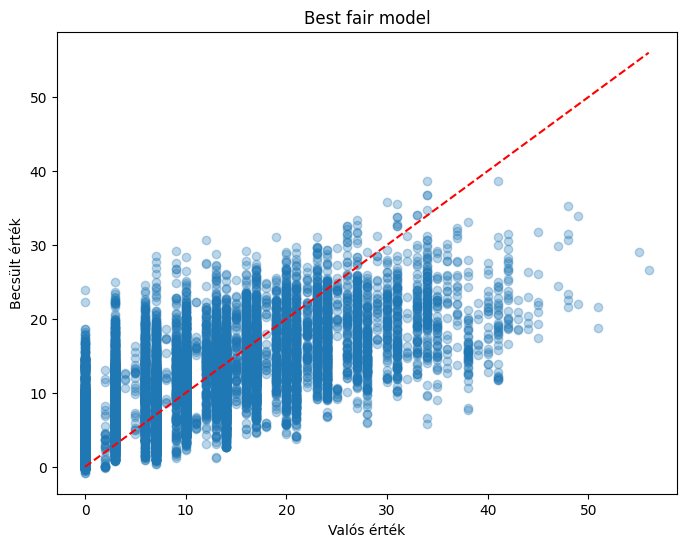

In [ ]:
# =========================
# 1. IMPORT
# =========================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# =========================
# 2. LOAD
# =========================
df = pd.read_csv("NFL Play by Play 2009-2016 (v3).csv", low_memory=False)

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

# =========================
# 3. TARGET
# =========================
target_candidates = ["posteamscore", "posteam_score", "posteam_score_post", "posteam_score_pre"]
target = next((c for c in target_candidates if c in df.columns), None)

if target is None:
    raise ValueError("Nem találtam target oszlopot.")

print("Target:", target)

# =========================
# 4. GROUP
# =========================
group_candidates = ["gameid", "game_id", "gsis_game_id"]
group_col = next((c for c in group_candidates if c in df.columns), None)

if group_col is None:
    raise ValueError("Nem találtam game azonosító oszlopot.")

print("Group column:", group_col)

# =========================
# 5. ROBUSZTUS FEATURE-ÖK
# =========================
base_features = [
    "down",
    "ydstogo",
    "qtr",
    "yardline_100",
    "game_seconds_remaining",
    "quarter_seconds_remaining",
    "half_seconds_remaining",
    "score_differential",
    "yards_gained",
    "drive",
    "ydsnet",
    "goal_to_go"
]

features = [f for f in base_features if f in df.columns]

# =========================
# 6. RENDEZÉS
# =========================
sort_cols = [group_col]
if "drive" in df.columns:
    sort_cols.append("drive")
if "play_id" in df.columns:
    sort_cols.append("play_id")

df = df.sort_values(sort_cols).reset_index(drop=True)

# =========================
# 7. FEATURE ENGINEERING
# =========================
if "drive" in df.columns:
    df["drive_progress"] = df.groupby([group_col, "drive"]).cumcount()
else:
    df["drive_progress"] = df.groupby(group_col).cumcount()

if "yards_gained" in df.columns:
    df["cumulative_yards"] = df.groupby(group_col)["yards_gained"].cumsum()
elif "ydsnet" in df.columns:
    df["cumulative_yards"] = df.groupby(group_col)["ydsnet"].cumsum()

if "game_seconds_remaining" in df.columns:
    max_time = df["game_seconds_remaining"].max()
    if pd.notna(max_time) and max_time != 0:
        df["time_ratio"] = df["game_seconds_remaining"] / max_time
    else:
        df["time_ratio"] = 0.0

if "score_differential" in df.columns and "time_ratio" in df.columns:
    df["pressure"] = df["score_differential"] * (1 - df["time_ratio"])

if "yardline_100" in df.columns:
    df["red_zone"] = (df["yardline_100"] < 20).astype(int)

if "ydsnet" in df.columns and "drive_progress" in df.columns:
    df["yds_per_play"] = df["ydsnet"] / (df["drive_progress"] + 1)

if "ydstogo" in df.columns:
    df["long_down"] = (df["ydstogo"] > 7).astype(int)

engineered_features = [
    "drive_progress",
    "cumulative_yards",
    "time_ratio",
    "pressure",
    "red_zone",
    "yds_per_play",
    "long_down"
]

features += [f for f in engineered_features if f in df.columns]
features = list(dict.fromkeys(features))

print("Features:", features)

# =========================
# 8. DATA
# =========================
data = df[features + [target]].copy()
data = data.dropna(subset=[target])

if len(data) > 80000:
    data = data.sample(n=80000, random_state=42)

# =========================
# 9. CLEAN
# =========================
for col in data.columns:
    if data[col].dtype == "object":
        data[col] = data[col].fillna("missing")
    else:
        data[col] = data[col].replace([np.inf, -np.inf], np.nan)
        data[col] = data[col].fillna(data[col].median())

# =========================
# 10. ENCODE
# =========================
for col in data.select_dtypes(include=["object"]).columns:
    if col != target:
        data[col] = data[col].astype("category").cat.codes

# =========================
# 11. X, y
# =========================
X = data[features]
y = data[target]

# =========================
# 12. SPLIT
# =========================
groups = df.loc[data.index, group_col]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# =========================
# 13. MODELL
# =========================
model = HistGradientBoostingRegressor(
    max_iter=400,
    max_depth=12,
    learning_rate=0.04,
    l2_regularization=1.5,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)

model.fit(X_train, y_train)

# =========================
# 14. PRED
# =========================
y_pred = model.predict(X_test)

# =========================
# 15. METRIKÁK
# =========================
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nBEST FAIR MODEL:")
print("RMSE:", rmse)
print("MAE :", mae)
print("R2  :", r2)

# =========================
# 16. PLOT
# =========================
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)
plt.xlabel("Valós érték")
plt.ylabel("Becsült érték")
plt.title("Best fair model")
plt.show()

Features: ['down', 'ydstogo', 'qtr', 'yrdline100', 'scorediff', 'yards_gained', 'drive', 'ydsnet', 'playtype', 'passattempt', 'rushattempt', 'epa', 'touchdown_prob', 'field_goal_prob', 'drive_progress', 'cumulative_yards', 'yds_per_play', 'red_zone']

FINAL PRO MODEL:
RMSE: 3.1197162659371833
MAE : 2.159609172417024
R2  : 0.8910779775162369


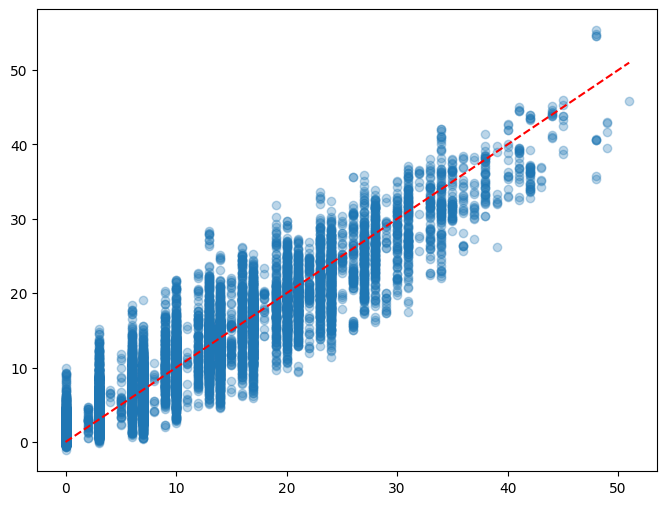

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


df = pd.read_csv("NFL Play by Play 2009-2016 (v3).csv", low_memory=False)

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
    .str.replace(".", "_", regex=False)
)


target = "posteamscore"
group_col = "gameid"


base_features = [
    "down",
    "ydstogo",
    "qtr",
    "yrdline100",
    "yards_gained",
    "drive",
    "ydsnet",
    "playtype",
    "passattempt",
    "rushattempt",
    "epa",
    "touchdown_prob",
    "field_goal_prob"
]

features = [f for f in base_features if f in df.columns]


df = df.sort_values([group_col, "drive"])

df["drive_progress"] = df.groupby([group_col, "drive"]).cumcount()

df["cumulative_yards"] = df.groupby(group_col)["yards_gained"].cumsum()

df["yds_per_play"] = df["ydsnet"] / (df["drive_progress"] + 1)

df["red_zone"] = (df["yrdline100"] < 20).astype(int)

features += [
    "drive_progress",
    "cumulative_yards",
    "yds_per_play",
    "red_zone"
]

features = [f for f in features if f in df.columns]

print("Features:", features)


data = df[features + [target]].copy()
data = data.dropna()

if len(data) > 80000:
    data = data.sample(n=80000, random_state=42)


for col in data.columns:
    if data[col].dtype == "object":
        data[col] = data[col].fillna("missing")
    else:
        data[col] = data[col].fillna(data[col].median())


for col in data.select_dtypes(include=["object"]).columns:
    if col != target:
        data[col] = data[col].astype("category").cat.codes

X = data[features]
y = data[target]


groups = df.loc[data.index, group_col]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]


model = HistGradientBoostingRegressor(
    max_iter=400,
    max_depth=12,
    learning_rate=0.04,
    random_state=42
)

model.fit(X_train, y_train)


y_pred = model.predict(X_test)


rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nFINAL PRO MODEL:")
print("RMSE:", rmse)
print("MAE :", mae)
print("R2  :", r2)


plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         "r--")
plt.show()